<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [VGI RDF Database](https://github.com/Query-farm/vgi-rdf)

Transactional SQL tables stored as RDF graphs

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-rdf/blob/main/notebooks/02_foreign_key_edits_move_graph_edges.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-rdf/blob/main/notebooks/README.md)

## Move a foreign key and follow the graph

Does reassigning a task move its RDF relationship, and does that change survive
reopening the database? We create **four synthetic tasks and three invented owners**,
inspect the SQL-to-RDF mapping, preview an edit with rollback, then commit it.
A read-only reattachment checks persistence. Task 104 deliberately has no owner;
we keep it in every count instead of silently dropping it in an inner join.

Everything happens in one disposable local directory owned by this notebook.
There is no external database, account or task-management service.

### Choose a destination

`TRANSFER_TO` selects Briar (2) or Cedar (3) for task 102, initially assigned to
Aster. It changes which relationship is moved; the number of tasks and the one
unassigned task should stay fixed.

In [1]:
TRANSFER_TO = 2  # Owner ID: 2 (Briar) or 3 (Cedar); experiment: 3

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.26":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.26"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("rdf")
import rdf_example as example  # noqa: E402 — download before import

example.configure(TRANSFER_TO, "TRANSFER_TO")
store = example.Store()
store_path = store.path
theme()
session = connect(globals())
native = session.connection
connection = example.TransactionSession(native)
%config SqlMagic.autocommit = False
%sql connection

### Open a store owned by this example

The release command is literal. The generated `store_path` is a fresh local
directory, reused only when this notebook reconnects. A transaction adapter
keeps consecutive SQL cells on the same native session. Closing the example
removes this directory and restores inherited RDF settings.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'rdf' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-rdf@v0.2.0 vgi-rdf-worker',
 database '{{store_path}}');

,Success


### Keep a nullable relationship visible

Foreign keys enforce the referenced owner when a value is present; `NULL` is
allowed because `owner_id` is nullable. The worker stores typed rows as RDF and
materializes a resource-to-resource edge for each non-null foreign key. Four tasks
therefore need only three owner edges. These are local teaching fixtures.

In [5]:
%%sql
CREATE TABLE rdf.main.owners(id INTEGER PRIMARY KEY, owner VARCHAR NOT NULL);
CREATE TABLE rdf.main.tasks(id INTEGER PRIMARY KEY, task VARCHAR NOT NULL,
 owner_id INTEGER REFERENCES rdf.main.owners(id));
INSERT INTO rdf.main.owners VALUES (1,'Aster'),(2,'Briar'),(3,'Cedar');
INSERT INTO rdf.main.tasks VALUES
 (101,'Inspect roof',1),(102,'Check pump',1),(103,'Read gauge',2),(104,'Draft plan',NULL);
CREATE TABLE owners AS SELECT * FROM rdf.main.rdf_rows('main','owners');
CREATE TABLE tasks_before AS SELECT * FROM rdf.main.rdf_rows('main','tasks');
CREATE TABLE edges_before AS SELECT * FROM rdf.main.rdf_quads(graph_iri:='urn:vgi:rdf:relationships');
CREATE TABLE ownership_before AS
 SELECT o.owner,count(t.id) AS task_count FROM owners o
 LEFT JOIN tasks_before t ON t.owner_id=o.id GROUP BY o.owner
 UNION ALL SELECT 'Unassigned',count(*) FROM tasks_before WHERE owner_id IS NULL;
SELECT id,task,owner_id FROM tasks_before ORDER BY id;

,id,task,owner_id
0,101,Inspect roof,1
1,102,Check pump,1
2,103,Read gauge,2
3,104,Draft plan,<NA>


### Discover predicates rather than guess identifiers

`rdf_tables` returns separate mappings for tables, columns and foreign-key
relationships. The foreign-key predicate points from a task **resource** to an
owner resource. The `owner_id` column predicate stores an integer **literal**;
these are different statements. We obtain both from the registry, and use
`rdf_rows` identities to join the actual stored quads back to typed rows.

In [6]:
%%sql
CREATE TABLE mapping AS SELECT * FROM rdf.main.rdf_tables(schema_name:='main');
SELECT table_name,kind,name,iri,target_iri FROM mapping
WHERE kind IN ('table','foreign_key') ORDER BY table_name,kind;
SET VARIABLE task_iri = (SELECT __rdf_iri FROM tasks_before WHERE id=102);
SET VARIABLE owner_predicate = (SELECT iri FROM mapping WHERE table_name='tasks' AND kind='foreign_key');

,Success


In [7]:
%%sql properties <<
CREATE TABLE stored_properties AS
 SELECT t.id,t.task,t.owner_id,count(q.subject) AS stored_columns
 FROM tasks_before t CROSS JOIN mapping m
 LEFT JOIN rdf.main.rdf_quads() q
 ON q.subject='<' || t.__rdf_iri || '>' AND q.predicate='<' || m.iri || '>'
 AND q.graph='<' || m.graph_iri || '>'
 WHERE m.table_name='tasks' AND m.kind='column'
 GROUP BY t.id,t.task,t.owner_id;
SELECT * FROM stored_properties ORDER BY id;

In [8]:
display(properties)
missing = properties.loc[properties.owner_id.isna()]
assert len(missing) == 1 and int(missing.stored_columns.iloc[0]) == 2
prose(
    "The unassigned task has **two stored column values**, versus three for each assigned task. "
    "SQL NULL omits the owner_id property triple; it does not remove the task or its stable row identity. "
    "These counts exclude internal row-identity triples by using only discovered column predicates."
)

,id,task,owner_id,stored_columns
0,101,Inspect roof,1,3
1,102,Check pump,1,3
2,103,Read gauge,2,3
3,104,Draft plan,<NA>,2


The unassigned task has **two stored column values**, versus three for each assigned task. SQL NULL omits the owner_id property triple; it does not remove the task or its stable row identity. These counts exclude internal row-identity triples by using only discovered column predicates.

### Preview, inspect, then roll back

An explicit transaction changes task 102's owner. A neighbor query inside the
same transaction must see the new edge. After rollback it must see the old one.
The function receives a stable row IRI and the discovered foreign-key predicate;
it follows an outgoing resource edge, not the scalar owner_id literal.

In [9]:
%%sql
BEGIN;
UPDATE rdf.main.tasks SET owner_id={{TRANSFER_TO}} WHERE id=102;

,Count


In [10]:
%%sql preview <<
SELECT o.id,o.owner FROM rdf.main.rdf_neighbors(getvariable('task_iri'),
 predicate_iri:=getvariable('owner_predicate'),direction:='out') e
JOIN owners o ON e.target=o.__rdf_iri;

In [11]:
%%sql
ROLLBACK;
CREATE TABLE rollback_edge AS
 SELECT * FROM rdf.main.rdf_neighbors(getvariable('task_iri'),
 predicate_iri:=getvariable('owner_predicate'),direction:='out');
SELECT t.id,t.owner_id,o.owner AS restored_owner
FROM rdf.main.tasks t JOIN rollback_edge e ON TRUE JOIN owners o ON e.target=o.__rdf_iri
WHERE t.id=102;

,id,owner_id,restored_owner
0,102,1,Aster


In [12]:
assert len(preview) == 1 and int(preview.id.iloc[0]) == TRANSFER_TO
assert native.execute("SELECT owner_id FROM rdf.main.tasks WHERE id=102").fetchone()[0] == 1
assert (
    native.execute(
        "SELECT count(*) FROM rollback_edge e JOIN owners o ON e.target=o.__rdf_iri WHERE o.id=1"
    ).fetchone()[0]
    == 1
)
prose(
    "The preview reached **" + preview.owner.iloc[0] + "**. Rollback restored both owner_id=1 and the edge to Aster. "
    "We now repeat the same edit and commit it."
)

The preview reached **Briar**. Rollback restored both owner_id=1 and the edge to Aster. We now repeat the same edit and commit it.

### Commit and reopen read-only

`COMMIT` publishes the changed RDF generation. `DETACH` closes this attachment;
reattaching the **same directory** with `read_only true` demonstrates persistence
without a second writer. The same literal released command works for both
attachments. This is a local persistence check, not a concurrent-client test.

In [13]:
%%sql
BEGIN;
UPDATE rdf.main.tasks SET owner_id={{TRANSFER_TO}} WHERE id=102;
COMMIT;
DETACH rdf;
ATTACH 'rdf' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-rdf@v0.2.0 vgi-rdf-worker',
 database '{{store_path}}', read_only true);

,Success


In [14]:
%%sql
CREATE TABLE tasks_after AS SELECT * FROM rdf.main.rdf_rows('main','tasks');
CREATE TABLE edges_after AS SELECT * FROM rdf.main.rdf_quads(graph_iri:='urn:vgi:rdf:relationships');
CREATE TABLE committed_edge AS
 SELECT * FROM rdf.main.rdf_neighbors(getvariable('task_iri'),
 predicate_iri:=getvariable('owner_predicate'),direction:='out');
CREATE TABLE ownership_after AS
 SELECT o.owner,count(t.id) AS task_count FROM owners o
 LEFT JOIN tasks_after t ON t.owner_id=o.id GROUP BY o.owner
 UNION ALL SELECT 'Unassigned',count(*) FROM tasks_after WHERE owner_id IS NULL;
SELECT t.id,t.task,t.owner_id,o.owner FROM tasks_after t LEFT JOIN owners o ON t.owner_id=o.id ORDER BY t.id;

,id,task,owner_id,owner
0,101,Inspect roof,1,Aster
1,102,Check pump,2,Briar
2,103,Read gauge,2,Briar
3,104,Draft plan,<NA>,None


In [15]:
%%sql before <<
SELECT * FROM ownership_before ORDER BY owner;

In [16]:
%%sql after <<
SELECT * FROM ownership_after ORDER BY owner;

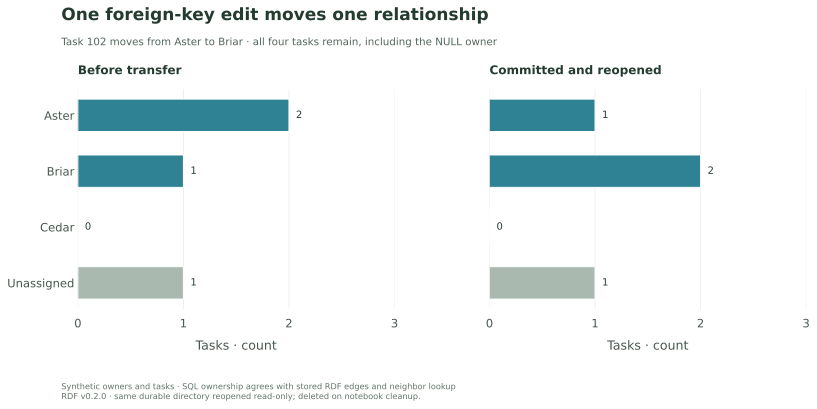

Task 102 is now assigned to **Briar** after reconnecting. Both snapshots contain **4 tasks**, including one unassigned task. Zero-task owners remain visible; a missing bar is not a missing owner record.

In [17]:
target_name = preview.owner.iloc[0]
example.plot_ownership(before, after, target_name)
prose(
    f"Task 102 is now assigned to **{target_name}** after reconnecting. "
    f"Both snapshots contain **{int(after.task_count.sum())} tasks**, including one unassigned task. "
    "Zero-task owners remain visible; a missing bar is not a missing owner record."
)

### Reconcile identities, predicates and edges

The checks compare complete multisets, not only totals. Exactly one old edge is
removed and one new edge added. The scalar column counts remain unchanged because
we replace a non-null owner with another non-null owner. Stable task IRIs must
survive both the edit and reopening. The NULL-owner task has no relationship edge.

In [18]:
%%sql checks <<
SELECT 'all task identities preserved' AS check_name,
 NOT EXISTS ((SELECT id,task,__rdf_iri FROM tasks_before EXCEPT ALL SELECT id,task,__rdf_iri FROM tasks_after)
 UNION ALL (SELECT id,task,__rdf_iri FROM tasks_after EXCEPT ALL SELECT id,task,__rdf_iri FROM tasks_before)) AS passed
UNION ALL SELECT 'three relationship edges',count(*)=3 FROM edges_after
UNION ALL SELECT 'three owners include zero counts',count(*)=3 FROM owners
UNION ALL SELECT 'one changed task',count(*)=1 FROM tasks_before b JOIN tasks_after a USING(id) WHERE b.owner_id IS DISTINCT FROM a.owner_id
UNION ALL SELECT 'selected destination persisted',owner_id={{TRANSFER_TO}} FROM tasks_after WHERE id=102
UNION ALL SELECT 'one old edge removed',count(*)=1 FROM (SELECT * FROM edges_before EXCEPT ALL SELECT * FROM edges_after)
UNION ALL SELECT 'one new edge added',count(*)=1 FROM (SELECT * FROM edges_after EXCEPT ALL SELECT * FROM edges_before)
UNION ALL SELECT 'neighbor matches typed owner',count(*)=1 FROM committed_edge e JOIN owners o ON e.target=o.__rdf_iri WHERE o.id={{TRANSFER_TO}}
UNION ALL SELECT 'NULL owner has no edge',NOT EXISTS(SELECT 1 FROM edges_after e JOIN tasks_after t ON e.subject='<' || t.__rdf_iri || '>' WHERE t.owner_id IS NULL)
UNION ALL SELECT 'all edges match SQL foreign keys',NOT EXISTS(
 (SELECT subject,predicate,object FROM edges_after EXCEPT ALL
 SELECT '<' || t.__rdf_iri || '>','<' || m.iri || '>','<' || o.__rdf_iri || '>'
 FROM tasks_after t JOIN owners o ON t.owner_id=o.id CROSS JOIN mapping m WHERE m.kind='foreign_key')
 UNION ALL
 (SELECT '<' || t.__rdf_iri || '>','<' || m.iri || '>','<' || o.__rdf_iri || '>'
 FROM tasks_after t JOIN owners o ON t.owner_id=o.id CROSS JOIN mapping m WHERE m.kind='foreign_key'
 EXCEPT ALL SELECT subject,predicate,object FROM edges_after))
UNION ALL SELECT 'nonnull columns agree with stored properties',bool_and(stored_columns=2+CASE WHEN owner_id IS NULL THEN 0 ELSE 1 END) FROM stored_properties
ORDER BY check_name;

In [19]:
display(checks)
assert len(checks) == 11 and checks.passed.notna().all() and checks.passed.all()
prose(
    f"All **{len(checks)}** persistence and mapping checks pass, alongside the rollback controls. "
    "The results support this single-store transaction example; they do not test concurrent writers, "
    "remote storage, cross-database atomicity or backup recovery."
)

,check_name,passed
0,NULL owner has no edge,True
1,all edges match SQL foreign keys,True
2,all task identities preserved,True
3,neighbor matches typed owner,True
4,nonnull columns agree with stored properties,True
5,one changed task,True
6,one new edge added,True
7,one old edge removed,True
8,selected destination persisted,True
9,three owners include zero counts,True


All **11** persistence and mapping checks pass, alongside the rollback controls. The results support this single-store transaction example; they do not test concurrent writers, remote storage, cross-database atomicity or backup recovery.

### Experiment: transfer to a previously idle owner

Change `TRANSFER_TO` from **2 to 3**, restart and run all. Predict Cedar gains one
task instead of Briar: all three owners, four tasks, three foreign-key edges and
one unassigned task remain. The same task IRI moves to a different owner IRI.
Compare the returned neighbor and complete edge checks, not only the bar heights.
The rollback still restores Aster before the committed transfer. Reset to **2**
to recover the published default.

In [20]:
assert native.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
native.execute("DETACH rdf")
session.close()
store.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-rdf](https://github.com/Query-farm/vgi-rdf)